## <font color='blue'>Machine Learning Coursework 2 (Finals)</font>

This coursework is worth 100 marks, amounting to 50% of the final course mark.

For coursework 2 you will be asked to train and evaluate at least three model classes on a dataset. You must choose both the model classes and the dataset you wish to work on. **Note: at least ONE of the three must be a model class see from topic 5 (unsupervised learning) or later**. You will be asked to provide an analysis of your results, of the relative strengths, weaknesses, and peculiarities of each individual model. Additional marks can be gained by expanding this coursework in an autonomous manner, as a work of research (see question 4. for suggestions).

#### You are free to use the sklearn library. 

Notes:
- Please use citations from literature to support your arguments wherever possible.
- Remember to comment all of your code ([see here for tips](https://stackabuse.com/commenting-python-code/)). You can also make use of Jupyter Markdown, where appropriate, to improve the layout of your code and documentation.
- Please add docstrings to all of your functions (so that users can get information on inputs/outputs and what each function does by typing SHIFT+TAB over the function name. For more detail on python docstrings, [see here](https://numpydoc.readthedocs.io/en/latest/format.html))
- When a question allows a free-form answer (e.g. what do you observe?), create a new markdown cell below and answer the question in the notebook. 
- Always save your notebook when you are done (this is not automatic)!
- Upload your completed notebook using the VLE.

Plagiarism: please make sure that the material you submit has been created by you. Any sources you use for code should be properly referenced. Your code will be checked for plagiarism using appropriate software.

### Marking 

The grades in this coursework are allocated approximately as follows:


| section                                            | mark   |  
|:---------------------------------------------------|--------|
| 1. Dataset                                         | 7      |
| 2. Models                                          | 18     |
| 3. Analysis                                        | 25     |
| 4. Self-directed research                          | 40     |
| Document quality: language, comments & code        | 10     |
| Total available                                    |**100** | 

In order to reach 50% (pass), you need to complete the first 3 parts, with 10 marks available on top of that for cleanliness and organisation. The marks in Part 4 are harder to obtain, to reach 70 and above, especially the last two points.

#### Remember!

Save your notebook as “CW2.ipynb”. It is a good idea to re-run the whole thing before saving and submitting. 

## <font color='blue'>1. Dataset [7 pts]</font>

In the following cell, briefly describe:
- Which dataset do you wish to work on, providing a link to the source used (it should be possible for the marker to obtain that dataset if needed, so do make sure to include instructions if that process is not straightforward);
- What kind of data the dataset contains;
- What kind of ML approach it is suited for;
- What are the features available, if any.

### Download the dataset
The dataset is available at: https://www.ksh.hu/stadat_files/gsz/hu/gsz0018.html  
It can be downloaded from "Menü" in .xlsx and in .csv

### Description of the dataset
I will be working with the Hungarian Central Statistical Office's dataset on enterprise performance indicators by small and medium enterprise (SME) categories. I focus on the analysis from compny developmet's perspective.
This official KSH dataset tracks core business health indicators across Hungarian enterprises, with detailed breakdowns by size category from 2013-2023.

**ML approaches the data is suited for**
1. **Unsupervised learning:** it provides multi-indicator, multi-year, multi-segment numeric vectors which is better for structure discovery and regime analysis rather than fine-grained prediction
   - Clustering years by SME structure to discover trends or cluster size classes by indicator profiles to quantify differences across the size segments
   - Dimensionality reduction (PCA) to find main axes of variation (e.g. export orientation, capital intensity), visualise trajectories of each size class over time, and interpret loadings for development insights
2. **Supervised regression**: with careful validation. Indicators are continues and economically meaningful; method changes imply potential level shifts, so simple, interpretable models with time-aware validation are preferred. Validation can be chronological splits (e.g. 2013-2019 train, 2020-2023 validate)
   - Linear regression with regularisations
   - Random Forest or Boosting given small-N constrainsts

**The features used from the dataset:**
- Enterprise size category (categorical)
- Year (temporal)
- Number of enterprises (numerical)
- Number of employees (numerical)
- Employee distribution (ratio)
- Revenue per employee (numerical)
- Net sales revenue (numerical)
- Value added (numerical)
- Export sales revenue (numerical)
- National economic investment (numerical)


In the cell below, load and process the dataset you are going to train your models on. The use of `scikit-learn` or equivalent libraries is permitted.

In [1]:
import pandas as pd

# Only read relevant data
df_gsz18 = pd.read_excel(
    "./resources/stadat-gsz0018-9.1.1.17-hu.xlsx",
    sheet_name="9.1.1.17.",
    skiprows=1,
    usecols=[
        'Kis- és középvállalkozási kategória',
        'Vállalkozások száma, darab',
        'Foglalkoztatottak létszáma, fő',
        'Egy foglalkoztatottra jutó árbevétel, ezer forint/fő',
        'Foglalkoztatottak létszámának megoszlása, %',
        'Értékesítés nettó árbevétele, millió forint',
        'Hozzáadott érték, millió forint',
        'Export-értékesítés árbevétele, millió forint',
        'Nemzetgazdasági beruházás, millió forint'    ]
)

# Rename columns to English
column_rename_map = {
    'Kis- és középvállalkozási kategória': 'Company Size Category',
    'Vállalkozások száma, darab': 'Number of Enterprises',
    'Foglalkoztatottak létszáma, fő': 'Number of Employees',
    'Egy foglalkoztatottra jutó árbevétel, ezer forint/fő': 'Revenue per Employee (thousand HUF/person)',
    'Foglalkoztatottak létszámának megoszlása, %': 'Employee Distribution (%)',
    'Értékesítés nettó árbevétele, millió forint': 'Net Sales Revenue (million HUF)',
    'Hozzáadott érték, millió forint': 'Value added (million HUF)',
    'Export-értékesítés árbevétele, millió forint': 'Export Sales Revenue (million HUF)',
    'Nemzetgazdasági beruházás, millió forint': 'National economic investment (million HUF)'
}
df_gsz18.rename(columns=column_rename_map, inplace=True)

# Make the dataset tidy
is_year = df_gsz18['Company Size Category'].astype(str).str.strip().str.match(r'^\d{4}$')
years = df_gsz18[is_year]['Company Size Category'].to_list()

# Add years as column (repeated for all 7 categories)
df_gsz18_data = df_gsz18[~is_year].reset_index(drop=True)
year_col = []
for y in years:
    year_col.extend([int(y)] * 7)
df_gsz18_data['Year'] = year_col

# Melt year to long format
value_vars = [col for col in df_gsz18_data.columns if col not in ['Company Size Category', 'Year']]
df_gsz18_final = pd.melt(df_gsz18_data,
                  id_vars=['Year', 'Company Size Category'],
                  value_vars=value_vars,
                  var_name='Indicator',
                  value_name='Value')

# Change company categories to English and create categorical variable
gsz18_category_order = [
    'Micro (0 employee)',
    'Micro (1 employee)',
    'Micro (2-9 employees)',
    'Small',
    'Medium',
    'Non-SME organization',
    'Total'
]

df_gsz18_final['Company Size Category'] = df_gsz18_final['Company Size Category'].str.strip()
gsz18_category_map = {
    '0 fős mikrovállalkozások': gsz18_category_order[0],
    '1 fős mikrovállalkozások': gsz18_category_order[1],
    '2–9 fős mikrovállalkozások': gsz18_category_order[2],
    'Kisvállalkozások': gsz18_category_order[3],
    'Középvállalkozások': gsz18_category_order[4],
    'Nem KKV körbe tartozó szervezetek': gsz18_category_order[5],
    'Összesen': gsz18_category_order[6]
}

df_gsz18_final['Company Size Category'] = df_gsz18_final['Company Size Category'].map(gsz18_category_map)

df_gsz18_final['Company Size Category'] = pd.Categorical(
    df_gsz18_final['Company Size Category'],
    categories=gsz18_category_order,
    ordered=True
)

df_gsz18_final.head()

,Year,Company Size Category,Indicator,Value
0,2013,Micro (0 employee),Number of Enterprises,9220.0
1,2013,Micro (1 employee),Number of Enterprises,392914.0
2,2013,Micro (2-9 employees),Number of Enterprises,173174.0
3,2013,Small,Number of Enterprises,29197.0
4,2013,Medium,Number of Enterprises,4961.0


#### Handle invalid values

In [2]:
# Make sure Year is numeric
pd.to_numeric(df_gsz18_final['Year'], errors='coerce').notna().all()

np.True_

In [3]:
# Value should be numerical too
df_gsz18_final['Value'] = pd.to_numeric(df_gsz18_final['Value'], errors='coerce')

# Check NaN
df_gsz18_final[ df_gsz18_final['Value'].isna()]

,Year,Company Size Category,Indicator,Value
77,2013,Micro (0 employee),Number of Employees,NaN
84,2014,Micro (0 employee),Number of Employees,NaN
91,2015,Micro (0 employee),Number of Employees,NaN
98,2016,Micro (0 employee),Number of Employees,NaN
105,2017,Micro (0 employee),Number of Employees,NaN
112,2018,Micro (0 employee),Number of Employees,NaN
119,2019,Micro (0 employee),Number of Employees,NaN
126,2020,Micro (0 employee),Number of Employees,NaN
133,2021,Micro (0 employee),Number of Employees,NaN
140,2022,Micro (0 employee),Number of Employees,NaN


0-employee companies don't have values for the following three indicators:
- Number of Employees
- Revenue per Employee (thousand HUF/person)
- Employee Distribution (%)  
As there are 0 employees, it makes sense to fill these values with 0, and then we can run the models without any problem.

In [4]:
df_gsz18_final['Value'] = df_gsz18_final['Value'].fillna(0)

Inspect the dataset:

In [5]:
indicators = df_gsz18_final.loc[:, 'Indicator'].dropna().unique().tolist()
indicators

['Number of Enterprises',
 'Number of Employees',
 'Revenue per Employee (thousand HUF/person)',
 'Employee Distribution (%)',
 'Net Sales Revenue (million HUF)',
 'Value added (million HUF)',
 'Export Sales Revenue (million HUF)',
 'National economic investment (million HUF)']

In [6]:
print("Structure Dataset Dimensions:", df_gsz18_final.shape)
print("\nAvailable Years:\n", ", ".join(map(str, sorted(df_gsz18_final['Year'].unique()))))
print("\nSize Categories:\n", ", ".join(df_gsz18_final['Company Size Category'].unique()))
print("\nIndicator Categories:\n", ", ".join(df_gsz18_final['Indicator'].unique()))
print(f"\nNumber of NaNs:\n {df_gsz18_final.isna().sum()}")
df_gsz18_final

Structure Dataset Dimensions: (616, 4)

Available Years:
 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023

Size Categories:
 Micro (0 employee), Micro (1 employee), Micro (2-9 employees), Small, Medium, Non-SME organization, Total

Indicator Categories:
 Number of Enterprises, Number of Employees, Revenue per Employee (thousand HUF/person), Employee Distribution (%), Net Sales Revenue (million HUF), Value added (million HUF), Export Sales Revenue (million HUF), National economic investment (million HUF)

Number of NaNs:
 Year                     0
Company Size Category    0
Indicator                0
Value                    0
dtype: int64


,Year,Company Size Category,Indicator,Value
0,2013,Micro (0 employee),Number of Enterprises,9220.000
1,2013,Micro (1 employee),Number of Enterprises,392914.000
2,2013,Micro (2-9 employees),Number of Enterprises,173174.000
3,2013,Small,Number of Enterprises,29197.000
4,2013,Medium,Number of Enterprises,4961.000
...,...,...,...,...
611,2023,Micro (2-9 employees),National economic investment (million HUF),206476.090
612,2023,Small,National economic investment (million HUF),704286.187
613,2023,Medium,National economic investment (million HUF),1465033.344
614,2023,Non-SME organization,National economic investment (million HUF),6466366.053


## <font color='blue'>2. Models [18 pts]</font>

Instantiate and train three different classes of models presented in the course in the cells below the corresponding header.

**At least ONE of the models must be from topic 5 and after.**

You are free to use `scikit-learn` and other packages where necessary.  

### Prepare data for models 

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Change my data to wide format
wide_df = df_gsz18_final.pivot_table(
    index = ['Year', 'Company Size Category'],
    columns = 'Indicator',
    values = 'Value',
    observed=False
).reset_index()

# Remove total
wide_df = wide_df[ wide_df['Company Size Category'] != 'Total' ].copy()

def scaled_train_test_split(test_size = 0.2):
    # Make sure test and train are separated from the beginning
    X_train, X_test = train_test_split(wide_df[indicators], test_size = test_size, random_state = 42)

    # It's important to standardise fearures as models using distances are very sensitive to scales (e.g. K-means, PCA)
   # Scaling also helps comparing the models later, and it doesn't hurt models that are not sensitive
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    return X_train_scaled, X_test_scaled

X_train, X_test = scaled_train_test_split()

### <font color='blue'>2.1 Model I [6 pts]: PCA</font>

Implement your first model and fit the dataset you loaded above. 

In [70]:
from sklearn.decomposition import PCA

def get_train_test_pca(n = 4, X_train = X_train, X_test = X_test):
    # Fit PCA on train set
    pca = PCA(n_components = n, svd_solver = 'randomized', random_state = 42)
    pca.fit(X_train)
    X_train_pca = pca.transform(X_train)
    
    # Use it for test
    X_test_pca = pca.transform(X_test)

    return X_train_pca, X_test_pca, pca

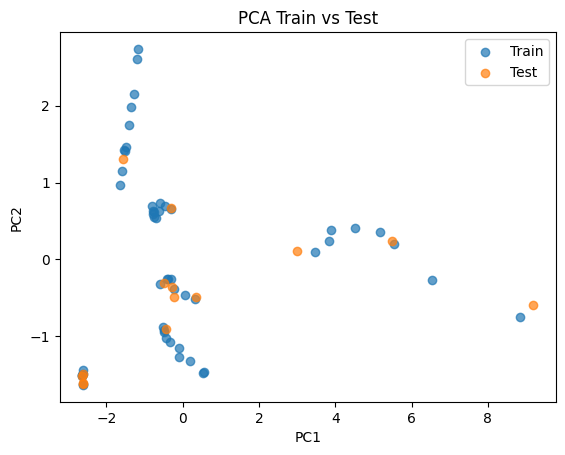

In [71]:
import matplotlib.pyplot as plt 

# Run with default values
X_train_pca, X_test_pca, pca = get_train_test_pca()

plt.scatter(X_train_pca[:,0], X_train_pca[:,1], label='Train', alpha=0.7)
plt.scatter(X_test_pca[:,0], X_test_pca[:,1], label='Test', alpha=0.7)
plt.legend()
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Train vs Test')
plt.show()

The scatter plots compares the train and test samples after PCA dimensionality reduction on the first two principal components (PC1 and PC2). The train and test points are both well spread out across the range of PC1, with overlap and similar coverage along PC2. No strong clustering or separation is apparent between the train and test subsets, suggesting that:
- The data splitting has maintained the underlying distribution of the original dataset
- There is no visible data leakage or unintentional bias in the train/test split
- Models built on these principal components should be able to generalize from the train set to unseen test data, since test samples fall in similar regions as the train set  

This balanced spread and overlap between train and test indicate a reliable PCA transformation and valid train-test partition, well supporting further machine learning analyses.

### <font color='blue'>2.2 Model II [6 pts]: K-Means Clustering</font>

Implement your second model and fit the dataset you loaded above. 

In [65]:
from sklearn.cluster import KMeans

def train_pred_k_means(k = 4, X_train = X_train, X_test = X_test):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    kmeans.fit(X_train)

    train_labels = kmeans.predict(X_train)
    test_labels = kmeans.predict(X_test)
    
    return train_labels, test_labels, kmeans

In [66]:
import numpy as np

train_labels, test_labels, kmeans = train_pred_k_means()
unique, counts = np.unique(train_labels, return_counts=True)
print(dict(zip(unique, counts)))

{np.int32(0): np.int64(27), np.int32(1): np.int64(8), np.int32(2): np.int64(7), np.int32(3): np.int64(10)}


The cluster assignments from K-means partition the train and test datasets into distinct groups based on feature similarity. The distribution of train samples across clusters (e.g., clusters 0 to 3) shows how the data is segmented by the algorithm.  

While clusters are distinct by definition, the cluster sizes are reasonably balanced without extreme skew, indicating meaningful groupings.  

This clustering reflects underlying structure in the data complementary to PCA’s dimension reduction. Comparing clusters and PCA components in later analysis will reveal how the groups differ in variation and feature influence.

### <font color='blue'>3.3 Model III [6 pts]: Isolation Forest</font>

Implement your third model and fit the dataset you loaded above. 

In [67]:
from sklearn.ensemble import IsolationForest

def train_test_isolation_forest(X_train = X_train, X_test = X_test):
    iso_forest = IsolationForest(random_state=42)
    iso_forest.fit(X_train)

    # =1 for anomalies, 1 for normal
    train_anomalies = iso_forest.predict(X_train)
    test_anomalies = iso_forest.predict(X_test)

    return train_anomalies, test_anomalies, iso_forest

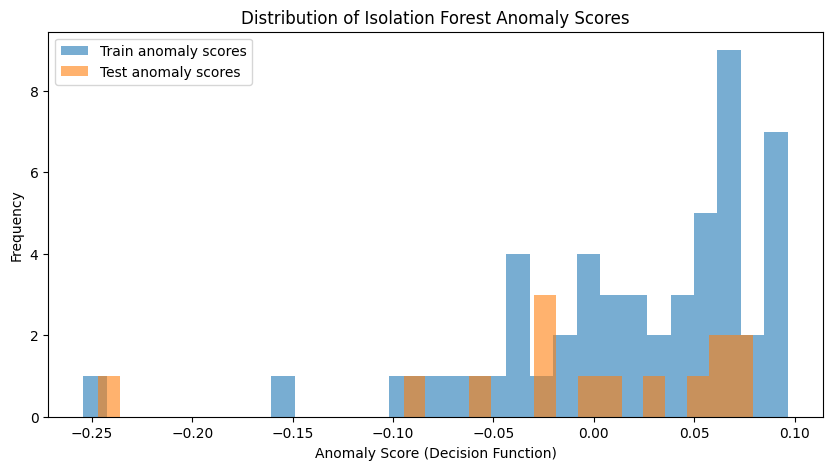

In [68]:
train_anomalies, test_anomalies, iso_forest = train_test_isolation_forest()

# Negative values indicate more anomalies
train_scores = iso_forest.decision_function(X_train)
test_scores = iso_forest.decision_function(X_test)

plt.figure(figsize=(10,5))
plt.hist(train_scores, bins=30, alpha=0.6, label='Train anomaly scores')
plt.hist(test_scores, bins=30, alpha=0.6, label='Test anomaly scores')
plt.xlabel('Anomaly Score (Decision Function)')
plt.ylabel('Frequency')
plt.title('Distribution of Isolation Forest Anomaly Scores')
plt.legend()
plt.show()

The histogram above compares the distribution of anomaly scores for the train and test sets as assigned by the Isolation Forest model. Both sets display a similar spread of scores, with most observations having positive anomaly scores (considered normal) and a few samples with negative scores (indicating potential anomalies).  
There is substantial overlap in the score distributions, suggesting that:
- The anomaly detection model treats train and test data similarly, with no major shift or bias introduced by the train-test split
- There is no evidence of data leakage or unexpected structural difference in anomaly scores between the train and test partitions
- The unsupervised anomaly detection process identifies outliers in a consistent way across both subsets, supporting the reliability of the model for flagging unusual records
- This similarity in anomaly score patterns between train and test data adds confidence to the validity of the modeling workflow and provides a solid foundation for further detailed anomaly analysis

## <font color='blue'>3. Analysis [25 pts]</font>

Present and analyse the results of the training above. 

### <font color='blue'>3.1 Results [5 pts]</font>

Present the performance of your models in a clear and succinct way.

This can be done manually (in markdown) or programmatically (storing results in a data structure during training runs and displaying its contents here).

#### PCA results

Number of PCA components retained: 4

Explained variance ratio per component:
  PC1: 0.7587
  PC2: 0.1696
  PC3: 0.0423
  PC4: 0.0237

Cumulative explained variance:
  PC1..PC1: 0.7587
  PC1..PC2: 0.9283
  PC1..PC3: 0.9706
  PC1..PC4: 0.9943


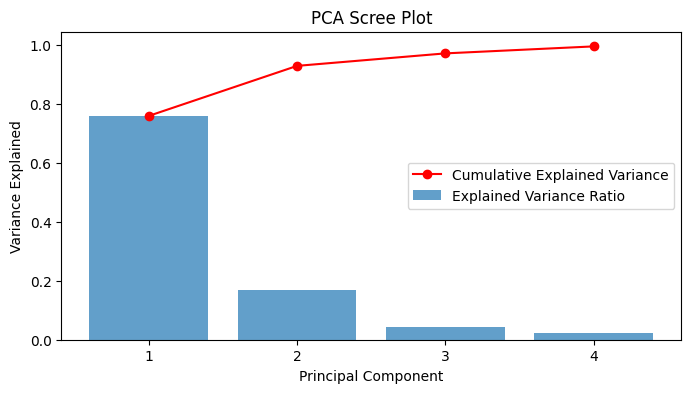

In [84]:
def describe_pca_variance(pca, X_train_pca = X_train_pca, X_test_pca = X_test_pca):
    # How much of the variance is explained by the components
    explained_var = pca.explained_variance_ratio_
    cumulative_var = np.cumsum(explained_var)

    print(f"Number of PCA components retained: {pca.n_components_}")
    print("\nExplained variance ratio per component:")
    for i, var_ratio in enumerate(explained_var):
        print(f"  PC{i+1}: {var_ratio:.4f}")
        
    print("\nCumulative explained variance:")
    for i, cum_var in enumerate(cumulative_var):
        print(f"  PC1..PC{i+1}: {cum_var:.4f}")

     # Plot it
    plt.figure(figsize=(8, 4))
    components = np.arange(1, pca.n_components_ + 1)
    plt.bar(components, explained_var, alpha=0.7, label='Explained Variance Ratio')
    plt.plot(components, cumulative_var, color='red', marker='o', label='Cumulative Explained Variance')
    plt.xlabel('Principal Component')
    plt.ylabel('Variance Explained')
    plt.title('PCA Scree Plot')
    plt.xticks(components)
    plt.legend()
    plt.show()

describe_pca_short(pca)

- 4 PCs retained
- Cumulative variance: 99.43%
- Two main components: PC1: 75.9%, PC2: 17%.

### <font color='blue'>3.2 Analysis & Comparison [20 pts]</font>

Analyse your results. This should include:

- Succinctly summarising the strengths and weaknesses, as well as potential problems, and their remedies, of the model classes you used, as seen in the course.
- Comparing the performance of the models you trained: accuracy is obviously the key metric to watch in most cases, but other factors can also play a role (such as computational cost, for instance: what if a complex model, that takes hours to train, only beats a much simpler and faster one by only a small margin?).
- Assess how each model is suited to the chosen dataset, and which model(s) is (are) the best.

You are free to organise this section as you see fit, depending on the requirements of your experiments. However, it is recommended to take extra care to make it clean and orderly, subdivising it into sections using markdown headings, for better readability. Feel free to use plots if relevant.

#### PCA analysis

Number of PCA components retained: 4

Explained variance ratio per component:
  PC1: 0.7587
  PC2: 0.1696
  PC3: 0.0423
  PC4: 0.0237

Cumulative explained variance:
  PC1..PC1: 0.7587
  PC1..PC2: 0.9283
  PC1..PC3: 0.9706
  PC1..PC4: 0.9943


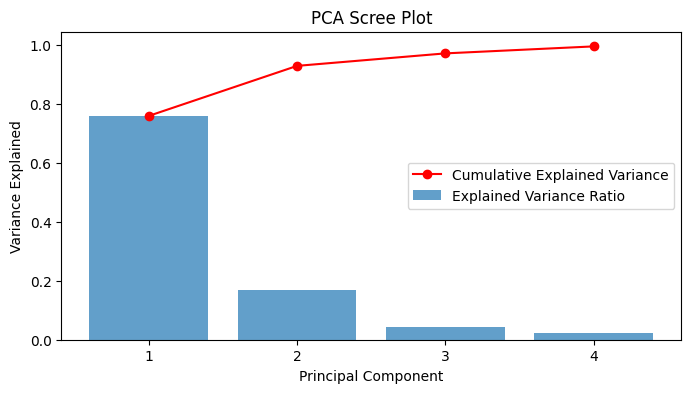


Top 3 loadings per principal component (absolute value):
  PC1 top contributing features: ['Value added (million HUF)', 'Net Sales Revenue (million HUF)', 'National economic investment (million HUF)', 'Export Sales Revenue (million HUF)', 'Revenue per Employee (thousand HUF/person)']
  PC2 top contributing features: ['Number of Enterprises', 'Number of Employees', 'Employee Distribution (%)', 'Revenue per Employee (thousand HUF/person)', 'National economic investment (million HUF)']
  PC3 top contributing features: ['Number of Enterprises', 'Employee Distribution (%)', 'Number of Employees', 'Export Sales Revenue (million HUF)', 'National economic investment (million HUF)']


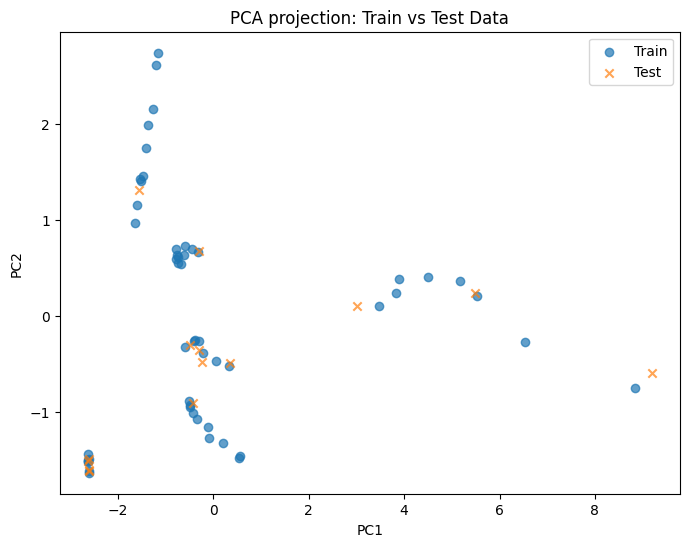

In [85]:
def describe_pca_var_and_features(pca, X_train_pca = X_train_pca, X_test_pca = X_test_pca):
    
    describe_pca_variance(pca)

    # Feature summary
    features = pd.DataFrame(pca.components_.T, columns=[f'PC{i+1}' for i in range(pca.n_components_)], index=indicators)
    print("\nTop 3 loadings per principal component (absolute value):")
    for i in range(min(3, pca.n_components_)):
        pc_loadings = features.iloc[:, i].abs().sort_values(ascending=False)
        top_features = pc_loadings.head(5).index.tolist()
        print(f"  PC{i+1} top contributing features: {top_features}")

    # Scatter plot of PC1 and PC2 for train and test
    plt.figure(figsize=(8, 6))
    plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], label='Train', alpha=0.7)
    plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], label='Test', alpha=0.7, marker='x')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    plt.title('PCA projection: Train vs Test Data')
    plt.legend()
    plt.show()

describe_pca_var_and_features(pca)

The PCA reduced the dataset to 4 principal components, retaining 99.43% of the total variance. The first principal component explains almost 76% of the variance, with PC2 adding another 17%, capturing most of the important information in just two dimensions. This strong drop-off, clearly visible in the scree plot, indicates that the primary structure of the data is dominated by a few underlying economic factors.

Looking at the top features PC1 is most influenced by:
- value added
- net sales revenue
- national economic investment
- export sales
- revenue per employee  

These features reflect overall financial size and output of companies, suggesting PC1 captures the scale and economic performance axis.

PC2 is dominated by structural/categorical metrics such as:
- number of enterprises
- number of employees
- employee distribution
- investment  

This component reflects business structure and workforce characteristics.

PC3 and the further components add only minor variation and mostly refine the patterns distinguished by PC1 and PC2.

The scatter plot of the first two principal components shows that both train and test sets have similar spread and overlap in the PCA-transformed space. This confirms that the split was done appropriately, maintaining the original data structure without introducing bias or leakage. There is no strong separation between the groups, suggesting consistent company behavior and indicator relationships across years and size classes.

- **Strengths:** PCA allows for both information-rich visualization and feature reduction, making subsequent modeling (clustering, anomaly detection) more efficient and interpretable
- **Weaknesses:** Interpretability of later components may decrease; nonlinear patterns (if present) are not captured

**Conclusion:** PCA is highly effective on this enterprise development dataset: it captures the majority of variation in a small number of dimensions that can be clearly tied to economic meaning. Its clear, intuitive output strongly supports further unsupervised learning and in-depth business indicator analyses.

## <font color='blue'>4. Self-directed research [40 pts]</font>

To obtain additional marks, pick one or more options below to flesh out and expand your experiments. As you can see, the marks below are significantly harder to obtain (require more work) than the first 50.

It is advised to keep the legibility and clarity of your coursework when adding new sections, so that the overall structure of the coursework remains coherent.

- **External dataset** <font color='blue'>(up to 3 pts)</font>: the use of a dataset that is not loaded from a library, but must be downloaded, then loaded and processed from raw data.
- **Advanced data pipelines** <font color='blue'>(up to 3 pts)</font>: experiments with the effect of noise, or data augmentation techniques, on training.
- **Data visualisation and exploration** <font color='blue'>(up to 3 pts)</font>: using relevant visualisation or plotting tools to deepen your analysis. Note that only producing a plot or visualisation will not yield many marks on its own. Those should be present to serve a greater purpose: that of understanding (the underlying structure of your data, and the behaviour of your models).
- **Advanced validation techniques** <font color='blue'>(up to 3 pts)</font>: going beyond train/test splits to strengthen model evaluation (such as the [the various categories of k-fold](https://scikit-learn.org/stable/modules/cross_validation.html#k-fold), if applicable, for instance when working on very small datasets).
- **Examples and/or study of model use** <font color='blue'>(up to 2 pts)</font>: given the ultimate goal of ML to achieve generalisation, can you subject your trained model(s) to the test? How do they behave when run on unseen data, or data far outside the distribution of the training set? Is it possible to demonstrate these behaviours in ways that are easily interpretable to humans. For example: given an image classifier, it is possible to plot a series of images from the training set, from the test set, and others, from the internet or done manually, and display the predictions alongside them? What do you notice? Where do(es) the model(s) succeed or fail, and how does this relate to the metrics recorded during training?
- **Manual implementations of model algorithms** <font color='blue'>(up to 8 pts)</font>: the exploration, for your own learning, and that of your reader(s), of the inner workings of one or several model classes without the use of a library (e.g. in plain `numpy`). It can be advantageous in these cases to perform comparisons with the API version in terms of performance, speed, memory footprint, as well as implementing checks to guarantee that your implementation is bug-free.
- **Additional model classes** <font color='blue'>(up to 8 pts)</font>: compare more than three model classes, *up to a total of 5*. If you go down that path, please add subsections under *2. Models*, and display the results and analyse them alongside the three required ones under *3. Analysis*, keeping the overall structure of the coursework untouched (don't create a separate 'additional models and analysis', but instead deal with all your models together). 
- **Engagement with the Machine Learning literature & innovation** <font color='blue'>(up to 10 pts)</font>: explore and use relevant research on a particular topic (studies on ML algorithms, specific learning problems or datasets), and integrate these results into your analysis. This could include implementing or porting a recent algorithmic improvement from a paper, and perform experiments on your chosen dataset, to see if it is possible to reproduce the improvements that this innovation is supposed to bring. Testing new ideas (at any point in your pipeline, from data processing to model architecture, and beyond) is welcome, even if it does not perform amazingly well: the key is always to try to perform rigorous comparisons between a known method and the new element you wish to introduce, in order to be able to show how well this new idea performs. Knowing for certain that something does not work well can be very useful, and is more often than not a stepping stone on the road to discovering something that does.